# D1 — Analyse des dossiers et de leur coordination

**Importation des bibliothèques**

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display, Markdown

**Configuration des sorties**

In [2]:
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/data_dictionary.csv').exists()), None)
assert ROOT is not None, 'Lancer le notebook depuis le dépôt ou un de ses sous-dossiers.'
OUT = ROOT / 'outputs/01_dossiers_et_coordination'
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 16)
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': False, 'font.size': 10})
print({'Python': platform.python_version(), 'pandas': pd.__version__,
       'numpy': np.__version__, 'matplotlib': matplotlib.__version__})

{'Python': '3.12.16', 'pandas': '2.3.3', 'numpy': '2.5.3', 'matplotlib': '3.11.2'}


**Fonctions de lecture et d’affichage**

In [3]:
def figure(nom):
    plt.tight_layout()
    plt.savefig(OUT / (nom + '.png'), dpi=150, bbox_inches='tight')
    plt.show()

def lire(nom):
    chemins = list((ROOT / 'data').rglob(nom + '.csv'))
    assert len(chemins) == 1, nom
    return pd.read_csv(chemins[0], dtype='string')

## 1. Découverte des fichiers

Pour commencer ce travail, j’ai pris le temps de découvrir les différents fichiers qui étaient mis à notre disposition. J’ai regardé ce qu’ils contenaient, mais aussi le nombre de lignes, les données manquantes et les doublons. Cette première découverte m’a permis de mieux comprendre les informations disponibles et de choisir les fichiers qui pouvaient m’aider à étudier les dossiers.

**Inventaire des fichiers CSV**

In [4]:
inventaire, manquants = [], []
for chemin in sorted((ROOT / 'data').rglob('*.csv')):
    table = pd.read_csv(chemin, dtype='string')
    inventaire.append({'fichier': chemin.relative_to(ROOT).as_posix(),
        'lignes': len(table), 'colonnes': len(table.columns),
        'doublons_exacts': int(table.duplicated().sum()),
        'cellules_manquantes': int(table.isna().sum().sum()),
        'sha256': hashlib.sha256(chemin.read_bytes()).hexdigest()})
    for col in table:
        manquants.append({'fichier': chemin.name, 'variable': col,
                         'manquants': int(table[col].isna().sum()),
                         'pct': round(100 * table[col].isna().mean(), 2)})
audit_fichiers = pd.DataFrame(inventaire)
audit_manquants = pd.DataFrame(manquants)
display(audit_fichiers.drop(columns='sha256'))

,fichier,lignes,colonnes,doublons_exacts,cellules_manquantes
0,data/data_dictionary.csv,355,8,0,5
1,data/ecology/bat_surveys.csv,4994,14,2,20
2,data/ecology/environmental_field_reports.csv,30,12,0,1
3,data/ecology/environmental_monthly.csv,4994,11,2,4815
4,data/ecology/monitoring_device_operations.csv,4994,11,2,4835
5,data/ecology/monitoring_sites.csv,64,14,0,65
6,data/ecology/orchard_surveys.csv,1250,11,2,1227
7,data/health/cardiac_recordings.csv,44,19,0,0
8,data/health/cardiac_signal_samples.csv,96925,4,0,0
9,data/health/clinical_encounters.csv,1069,12,2,243


**Chargement des données**

In [5]:
dictionary = lire('data_dictionary')
noms = ['regulatory_case_events', 'site_access_case_events', 'shipments',
        'monitoring_sites', 'institutional_memos', 'clinical_encounters',
        'purchase_order_lines', 'registered_entities']
bruts = {nom: lire(nom) for nom in noms}
display(dictionary[dictionary.file_name.isin([n + '.csv' for n in noms])]
        [['file_name', 'field_name', 'logical_type', 'key_role', 'description']])

,file_name,field_name,logical_type,key_role,description
0,clinical_encounters.csv,encounter_number,identifier,primary_or_composite_key,Source-local encounter identifier.
1,clinical_encounters.csv,patient_number,identifier,non_key,Source-local patient identifier used within the clinical system.
2,clinical_encounters.csv,encounter_start,date_or_datetime,non_key,Encounter start.
3,clinical_encounters.csv,encounter_end,date_or_datetime,non_key,Encounter end.
4,clinical_encounters.csv,facility_license_number,identifier,non_key,Facility license number.
...,...,...,...,...,...
339,institutional_memos.csv,text,long_text,non_key,Full document body as stored by the source repository.
340,institutional_memos.csv,related_purchase_order,categorical_or_text,non_key,Related purchase order.
341,institutional_memos.csv,related_shipment_number,identifier,non_key,Related shipment number.
342,institutional_memos.csv,related_case_number,identifier,non_key,Related case number.


**Valeurs manquantes**

In [6]:
display(audit_manquants.query('manquants > 0').loc[
    lambda d: d.fichier.isin([n + '.csv' for n in noms])])

,fichier,variable,manquants,pct
63,monitoring_sites.csv,elevation_m,1,1.56
68,monitoring_sites.csv,programme_end_date,64,100.00
110,clinical_encounters.csv,referral_source,3,0.28
115,clinical_encounters.csv,follow_up_date,240,22.45
235,purchase_order_lines.csv,declared_cost_center,3,0.46
240,shipments.csv,arrival_time,17,3.76
261,institutional_memos.csv,related_purchase_order,25,83.33
262,institutional_memos.csv,related_shipment_number,22,73.33
263,institutional_memos.csv,related_case_number,20,66.67
330,registered_entities.csv,parent_registration_number,24,100.00


## 2. Préparation des données

Après avoir repéré les fichiers utiles, j’ai commencé à préparer les données. J’ai d’abord vérifié les dates et les identifiants pour être sûr de pouvoir suivre chaque dossier correctement. Ensuite, j’ai retiré les lignes qui étaient identiques et j’ai harmonisé l’écriture des activités et des statuts. Cette étape était nécessaire pour comparer les événements sans être gêné par de simples différences d’écriture.

**Conversion des dates**

In [7]:
FORMATS = ['%Y-%m-%dT%H:%M:%S', '%Y-%m-%d %H:%M:%S',
           '%Y-%m-%d', '%Y/%m/%d %H:%M:%S', '%Y/%m/%d',
           '%d-%b-%Y %H:%M:%S', '%d-%b-%Y', '%d/%m/%Y %H:%M:%S', '%d/%m/%Y']
audit_dates = []

def dates(s, source, variable):
    s = s.astype('string').str.strip().replace('', pd.NA)
    resultat = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for fmt in FORMATS:
        masque = resultat.isna() & s.notna()
        resultat.loc[masque] = pd.to_datetime(s.loc[masque], format=fmt, errors='coerce')
    audit_dates.append({'source': source, 'variable': variable, 'lignes': len(s),
        'absentes': int(s.isna().sum()), 'invalides': int((s.notna() & resultat.isna()).sum()),
        'valeurs_invalides': ' | '.join(s[s.notna() & resultat.isna()].unique())})
    return resultat

**Doublons et identifiants**

In [8]:
cles = {'regulatory_case_events': ['regulatory_event_id'],
        'site_access_case_events': ['access_event_id'],
        'shipments': ['shipment_number', 'shipment_leg'],
        'monitoring_sites': ['site_code'], 'institutional_memos': ['document_id'],
        'clinical_encounters': ['encounter_number'],
        'purchase_order_lines': ['purchase_order_number', 'purchase_order_line'],
        'registered_entities': ['registration_number']}
tables, controles = {}, []
for nom, brut in bruts.items():
    d = brut.drop_duplicates().copy()
    cle = cles[nom]
    controles.append({'table': nom, 'brut': len(brut), 'net': len(d),
        'doublons_retires': len(brut)-len(d),
        'cles_absentes': int(d[cle].isna().any(axis=1).sum()),
        'cles_repetees_apres_nettoyage': int(d.duplicated(cle, keep=False).sum())})
    assert not d[cle].isna().any().any(), f'Clé manquante : {nom}'
    assert not d.duplicated(cle).any(), f'Clé conflictuelle : {nom}'
    tables[nom] = d
audit_cles = pd.DataFrame(controles)
display(audit_cles)

,table,brut,net,doublons_retires,cles_absentes,cles_repetees_apres_nettoyage
0,regulatory_case_events,233,232,1,0,0
1,site_access_case_events,413,412,1,0,0
2,shipments,452,450,2,0,0
3,monitoring_sites,64,64,0,0,0
4,institutional_memos,30,30,0,0,0
5,clinical_encounters,1069,1067,2,0,0
6,purchase_order_lines,651,650,1,0,0
7,registered_entities,24,24,0,0,0


Après le nettoyage, il reste 232 événements réglementaires et 412 événements d’accès. Les identifiants contrôlés sont uniques. Les copies retirées ne sont donc pas comptées dans les parcours.

**Préparation des événements**

In [9]:
def journal(nom, col_cas, col_id, domaine):
    d = tables[nom].copy()
    d['date'] = dates(d.event_time, nom, 'event_time')
    for col in ['activity', 'previous_status', 'new_status']:
        d[col + '_norm'] = d[col].str.strip().str.lower()
    d = d.rename(columns={col_cas: 'dossier', col_id: 'event_id'})
    d['domaine'] = domaine
    assert d[['date', 'dossier', 'activity_norm']].notna().all().all()
    d['egalite_horodatage'] = d.duplicated(['dossier', 'date'], keep=False)
    d = d.sort_values(['dossier', 'date', 'event_id'], kind='stable').reset_index(drop=True)
    g = d.groupby('dossier', sort=False)
    d['precedente'] = g.activity_norm.shift()
    d['delai_jours'] = g.date.diff().dt.total_seconds() / 86400
    d['statut_attendu'] = g.new_status_norm.shift()
    d['rupture_statut'] = (d.statut_attendu.notna() & d.previous_status_norm.notna()
                          & d.statut_attendu.ne(d.previous_status_norm)).fillna(False)
    assert d.delai_jours.dropna().ge(0).all()
    return d

**Contrôle des événements**

In [10]:
reg = journal('regulatory_case_events', 'case_number', 'regulatory_event_id', 'Réglementaire')
acc = journal('site_access_case_events', 'access_case_number', 'access_event_id', 'Accès')
for d in [reg, acc]:
    print(d.domaine.iloc[0], ':', len(d), 'événements ;', d.dossier.nunique(), 'dossiers ;',
          int(d.egalite_horodatage.sum()), 'événements à horodatage partagé')
    display(d.loc[d.activity.ne(d.activity_norm), ['event_id', 'activity', 'activity_norm']])
display(pd.DataFrame(audit_dates))

Réglementaire : 232 événements ; 40 dossiers ; 0 événements à horodatage partagé


,event_id,activity,activity_norm
7,RGE-000190,Triage_Review,triage_review
94,RGE-000175,Technical_Review,technical_review


Accès : 412 événements ; 60 dossiers ; 0 événements à horodatage partagé


,event_id,activity,activity_norm
105,ACE-000032,REQUEST_SUBMITTED,request_submitted
186,ACE-000071,REQUEST_SUBMITTED,request_submitted
325,ACE-000288,ACCESS_COMPLETED,access_completed


,source,variable,lignes,absentes,invalides,valeurs_invalides
0,regulatory_case_events,event_time,232,0,0,
1,site_access_case_events,event_time,412,0,0,


Les deux journaux contiennent 40 dossiers réglementaires et 60 demandes d’accès. Toutes leurs dates d’événement ont pu être converties.

Pendant le nettoyage, j’ai fait attention à conserver les activités qui se répétaient à des dates différentes. Même si leur nom est le même, elles peuvent correspondre à deux moments distincts du parcours d’un dossier. Les délais que j’ai calculés par la suite représentent donc le temps écoulé entre les événements enregistrés dans les fichiers.

## 3. Parcours et durées des dossiers

Une fois les données préparées, j’ai pu reconstituer le parcours de chaque dossier. Pour cela, j’ai remis les événements dans l’ordre de leurs dates, puis j’ai calculé le temps passé entre les différentes étapes. J’ai étudié séparément les dossiers réglementaires et les demandes d’accès, car ils ne suivent pas forcément le même fonctionnement. Cela m’a permis de mieux comprendre les durées observées dans chaque groupe.

**Parcours et durées**

In [11]:
def resumer(evenements):
    groupes = evenements.groupby("dossier")
    resume = groupes.agg(
        debut=("date", "min"),
        fin=("date", "max"),
        nb_evenements=("event_id", "size"),
        parcours=("activity_norm", lambda valeurs: " → ".join(valeurs)),
        references=("event_id", lambda valeurs: " | ".join(valeurs)),
        ruptures=("rupture_statut", "sum"),
        egalites=("egalite_horodatage", "sum"),
    )

    resume["duree_jours"] = (
        resume["fin"] - resume["debut"]
    ).dt.total_seconds() / 86400

    if "case_category" in evenements.columns:
        categories = groupes["case_category"]
        assert categories.nunique().le(1).all()
        resume["categorie"] = categories.first()
    else:
        resume["categorie"] = "demande_acces"

    resume["domaine"] = evenements["domaine"].iloc[0]
    resume["effectif_variante"] = (
        resume.groupby(["categorie", "parcours"])["parcours"].transform("size")
    )
    resume["effectif_categorie"] = (
        resume.groupby("categorie")["parcours"].transform("size")
    )
    resume["support_variante"] = (
        resume["effectif_variante"] / resume["effectif_categorie"]
    )
    return resume.reset_index()

**Statistiques des durées**

In [12]:
resume_reg, resume_acc = resumer(reg), resumer(acc)
resumes = pd.concat([resume_reg, resume_acc], ignore_index=True)
display(resumes.groupby(['domaine', 'categorie']).duree_jours.describe())

count       mean       std   min   25%  \
domaine       categorie                                                         
Accès         demande_acces             60.0  21.625000  8.356148  12.0  17.0   
Réglementaire corporate_transparency     5.0  18.000000  0.000000  18.0  18.0   
              environmental_complaint   13.0  18.846154  1.463224  18.0  18.0   
              medical_audit              5.0  18.000000  0.000000  18.0  18.0   
              procurement_review         5.0  18.000000  0.000000  18.0  18.0   
              shipment_inspection        7.0  18.142857  0.377964  18.0  18.0   
              wildlife_inspection        5.0  35.000000  0.000000  35.0  35.0   

                                        50%        75%        max  
domaine       categorie                                            
Accès         demande_acces            17.0  34.083333  34.083333  
Réglementaire corporate_transparency   18.0  18.000000  18.000000  
              environmental_complaint  18.0  19.000000  22.000000  
              medical_audit            18.0  18.000000  18.000000  
              procurement_review       18.0  18.000000  18.000000  
              shipment_inspection      18.0  18.000000  19.000000  
              wildlife_inspection      35.0  35.000000  35.000000

La durée médiane est de 18 jours pour les dossiers réglementaires et de 17 jours pour les demandes d’accès. Je compare ensuite les durées à l’intérieur de chaque catégorie.

**Variantes et délais**

In [13]:
variantes = (resumes.groupby(['domaine', 'categorie', 'parcours'], as_index=False)
             .agg(effectif=('dossier', 'size'), support=('support_variante', 'first')))
display(variantes.sort_values(['domaine', 'effectif'], ascending=[True, False]))
display(reg[['dossier', 'event_id', 'date', 'activity_norm', 'delai_jours']].head(15))

,domaine,categorie,parcours,effectif,support
4,Accès,demande_acces,request_submitted → technical_review → wildlife_review → authorization_granted → access_started ...,28,0.466667
1,Accès,demande_acces,request_submitted → technical_review → authorization_granted → access_started → access_completed...,12,0.200000
6,Accès,demande_acces,request_submitted → technical_review → wildlife_review → security_review → authorization_granted...,11,0.183333
2,Accès,demande_acces,request_submitted → technical_review → wildlife_review → authorization_denied → closure_recorded,4,0.066667
0,Accès,demande_acces,request_submitted → technical_review → authorization_denied → closure_recorded,2,0.033333
3,Accès,demande_acces,request_submitted → technical_review → wildlife_review → authorization_denied → request_submitte...,2,0.033333
5,Accès,demande_acces,request_submitted → technical_review → wildlife_review → security_review → authorization_denied ...,1,0.016667
7,Réglementaire,corporate_transparency,case_opened → evidence_received → triage_review → technical_review → case_closed,5,1.000000
8,Réglementaire,environmental_complaint,case_opened → evidence_received → triage_review → technical_review → case_closed,5,0.384615
9,Réglementaire,environmental_complaint,case_opened → evidence_received → triage_review → technical_review → finding_issued → case_closed,5,0.384615


,dossier,event_id,date,activity_norm,delai_jours
0,REG-2016-0018,RGE-000104,2016-04-10 10:00:00,case_opened,NaN
1,REG-2016-0018,RGE-000105,2016-04-12 10:00:00,evidence_received,2.0
2,REG-2016-0018,RGE-000106,2016-04-14 10:00:00,triage_review,2.0
3,REG-2016-0018,RGE-000107,2016-04-20 10:00:00,technical_review,6.0
4,REG-2016-0018,RGE-000108,2016-04-28 10:00:00,case_closed,8.0
5,REG-2016-0033,RGE-000188,2016-05-03 10:00:00,case_opened,NaN
6,REG-2016-0033,RGE-000189,2016-05-05 10:00:00,evidence_received,2.0
7,REG-2016-0033,RGE-000190,2016-05-07 10:00:00,triage_review,2.0
8,REG-2016-0033,RGE-000191,2016-05-13 10:00:00,technical_review,6.0
9,REG-2016-0033,RGE-000192,2016-05-21 10:00:00,case_closed,8.0


**Graphiques des durées**

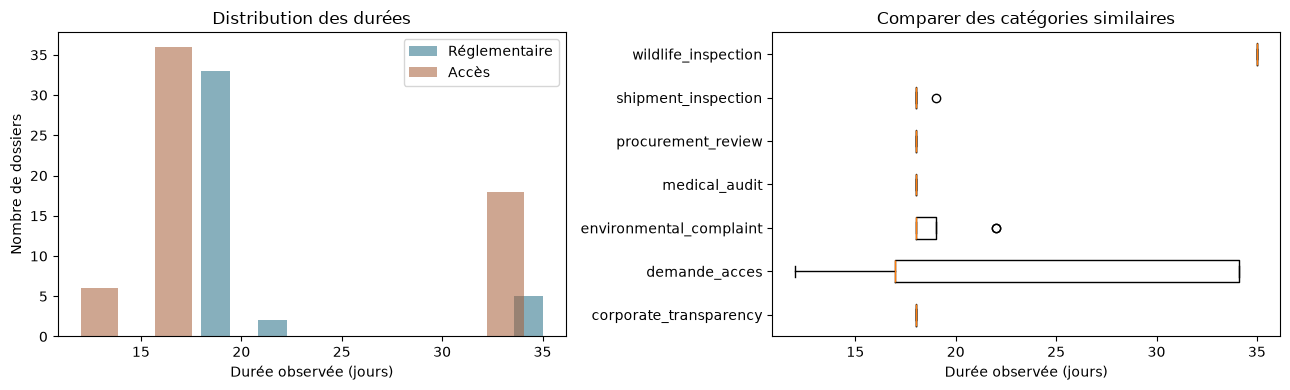

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for r, couleur in [(resume_reg, '#256d85'), (resume_acc, '#a75d38')]:
    axes[0].hist(r.duree_jours, bins=12, alpha=.55, label=r.domaine.iloc[0], color=couleur)
axes[0].set(xlabel='Durée observée (jours)', ylabel='Nombre de dossiers', title='Distribution des durées')
axes[0].legend()
groupes = list(resumes.groupby('categorie'))
axes[1].boxplot([g.duree_jours for _, g in groupes], orientation="horizontal")
axes[1].set_yticks(range(1, len(groupes)+1), [n for n, _ in groupes])
axes[1].set(xlabel='Durée observée (jours)', title='Comparer des catégories similaires')
figure('01_durees')

## 4. Enchaînement des activités

Après avoir étudié les dossiers un par un, j’ai voulu savoir quelles étapes revenaient le plus souvent et dans quel ordre elles apparaissaient. J’ai utilisé une méthode vue en cours pour compter les passages d’une activité à une autre. J’ai ensuite représenté ces résultats dans des tableaux et des graphes. J’ai essayé plusieurs seuils afin de rendre les graphes plus lisibles et de voir si certains liens disparaissaient lorsque je ne gardais que les passages les plus marqués.

**Transitions entre activités**

In [15]:
def transitions(evenements):
    transitions_successives = evenements.dropna(subset=["precedente"])
    comptes = (
        transitions_successives
        .groupby(["precedente", "activity_norm"])
        .agg(
            poids=("event_id", "size"),
            nb_dossiers=("dossier", "nunique"),
            delai_median=("delai_jours", "median"),
            delai_max=("delai_jours", "max"),
        )
        .reset_index()
    )
    comptes = comptes.rename(
        columns={"precedente": "depart", "activity_norm": "arrivee"}
    )

    poids_par_lien = comptes.set_index(["depart", "arrivee"])["poids"].to_dict()
    comptes["poids_inverse"] = [
        poids_par_lien.get((arrivee, depart), 0)
        for depart, arrivee in zip(comptes["depart"], comptes["arrivee"])
    ]
    comptes["dependance"] = (
        (comptes["poids"] - comptes["poids_inverse"])
        / (comptes["poids"] + comptes["poids_inverse"] + 1)
    )
    boucles = comptes["depart"].eq(comptes["arrivee"])
    comptes.loc[boucles, "dependance"] = np.nan

    nombre_dossiers = evenements["dossier"].nunique()
    comptes["support_dossiers"] = comptes["nb_dossiers"] / nombre_dossiers
    sorties = comptes.groupby("depart")["poids"].transform("sum")
    comptes["frequence_conditionnelle"] = comptes["poids"] / sorties

    assert comptes["poids"].sum() == len(evenements) - nombre_dossiers
    return comptes.sort_values("poids", ascending=False)

trans_reg = transitions(reg)
trans_acc = transitions(acc)

**Matrices des transitions**

In [16]:
def matrice(t, titre, nom):
    labels = sorted(set(t.depart) | set(t.arrivee))
    m = t.pivot(index='depart', columns='arrivee', values='poids').reindex(index=labels, columns=labels).fillna(0)
    fig, ax = plt.subplots(figsize=(10, 7))
    im = ax.imshow(m, cmap='Blues')
    ax.set_xticks(range(len(labels)), labels, rotation=55, ha='right')
    ax.set_yticks(range(len(labels)), labels)
    for (i, j), valeur in np.ndenumerate(m.to_numpy()):
        if valeur: ax.text(j, i, str(int(valeur)), ha='center', va='center', color='black')
    ax.set(xlabel='Activité suivante', ylabel='Activité précédente', title=titre)
    fig.colorbar(im, ax=ax, label='Occurrences')
    figure(nom)

**Graphes des parcours**

In [17]:
def graphe(t, ordre, titre, nom, seuil=None):
    edges = t if seuil is None else t.loc[t.dependance.ge(seuil)]
    presents = set(edges.depart) | set(edges.arrivee)
    nodes = [n for n in ordre if n in presents]
    angles = np.linspace(np.pi/2, np.pi/2+2*np.pi, len(nodes), endpoint=False)
    pos = {n: np.array([np.cos(a), np.sin(a)]) for n, a in zip(nodes, angles)}
    fig, ax = plt.subplots(figsize=(12, 9))
    for e in edges.itertuples():
        a, b = pos[e.depart], pos[e.arrivee]
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle='-|>', mutation_scale=14,
            shrinkA=25, shrinkB=25, linewidth=1+2*e.poids/t.poids.max(),
            color='#678394', alpha=.8, connectionstyle='arc3,rad=0.12'))
        mid = (a+b)/2
        delta = b-a
        mid += np.array([delta[1], -delta[0]])*.08
        ax.text(*mid, str(e.poids), fontsize=9,
                bbox=dict(facecolor='white', alpha=.9, edgecolor='none'))
    for n, p in pos.items():
        ax.scatter(*p, s=750, color='#e3eff2', edgecolor='#256d85', zorder=3)
        ax.text(*(p*1.19), n.replace('_', '\n'), ha='center', va='center', fontsize=9)
    ax.set(xlim=(-1.6, 1.6), ylim=(-1.5, 1.5), title=titre)
    ax.axis('off')
    figure(nom)

**Comparaison des seuils**

,depart,arrivee,poids,nb_dossiers,delai_median,delai_max,poids_inverse,dependance,support_dossiers,frequence_conditionnelle
0,case_opened,evidence_received,40,40,2.0,4.0,0,0.975610,1.000,1.000000
1,evidence_received,triage_review,40,40,2.0,2.0,0,0.975610,1.000,1.000000
12,triage_review,technical_review,23,23,6.0,6.0,0,0.958333,0.575,0.575000
6,inspection_scheduled,inspection_completed,17,17,5.0,5.0,0,0.944444,0.425,1.000000
11,triage_review,inspection_scheduled,17,17,3.0,3.0,0,0.944444,0.425,0.425000
8,technical_review,case_closed,15,15,8.0,8.0,0,0.937500,0.375,0.652174
2,finding_issued,case_closed,11,11,9.0,20.0,0,0.916667,0.275,1.000000
3,inspection_completed,case_closed,10,10,6.0,6.0,0,0.909091,0.250,0.588235
4,inspection_completed,finding_issued,6,6,3.0,3.0,0,0.857143,0.150,0.352941
9,technical_review,finding_issued,5,5,4.0,4.0,0,0.833333,0.125,0.217391


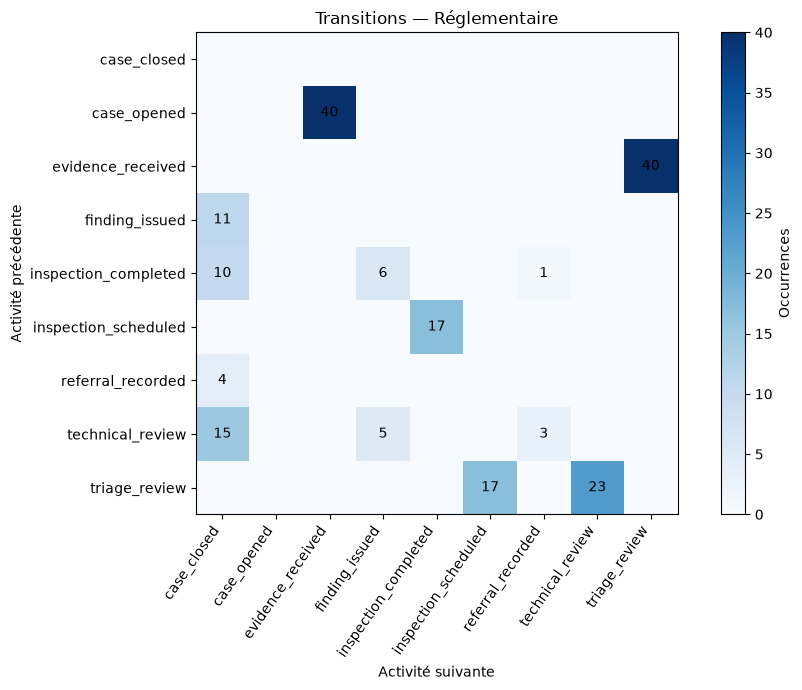

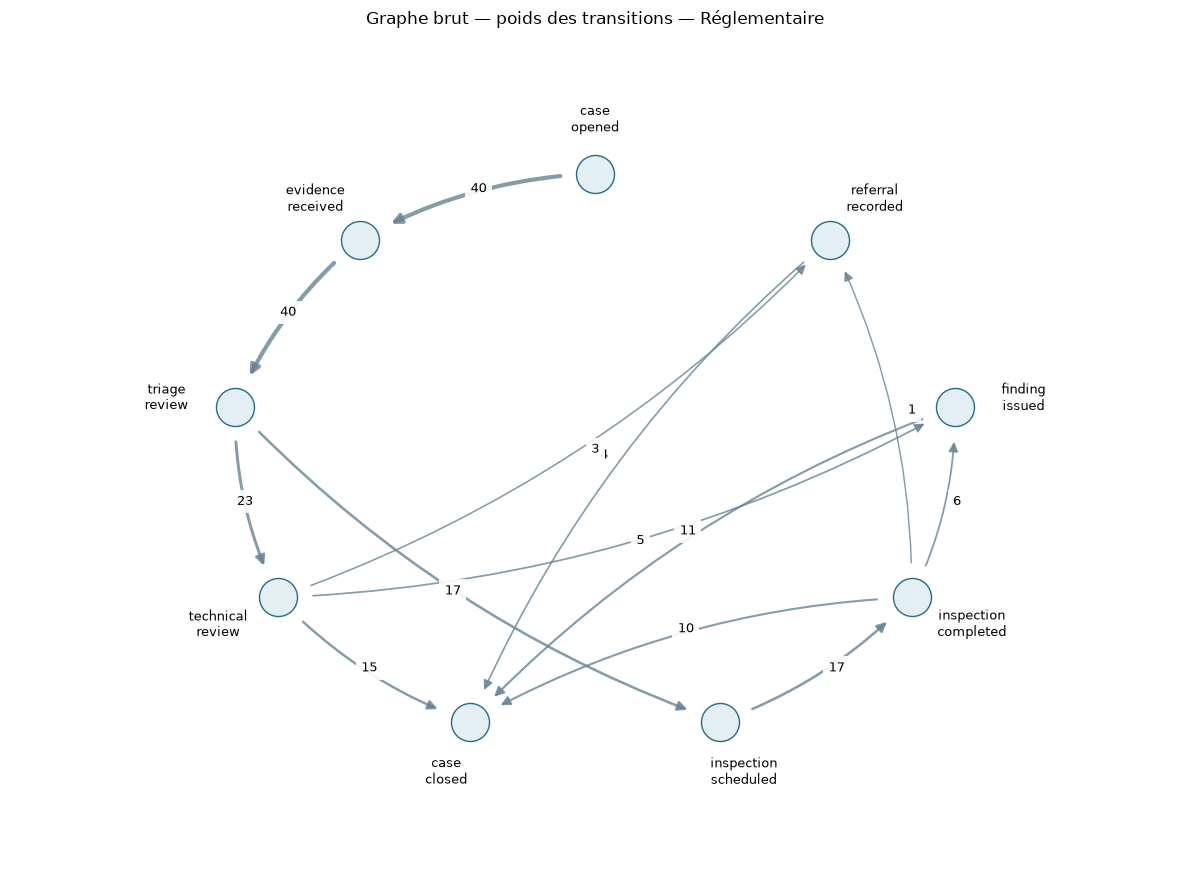

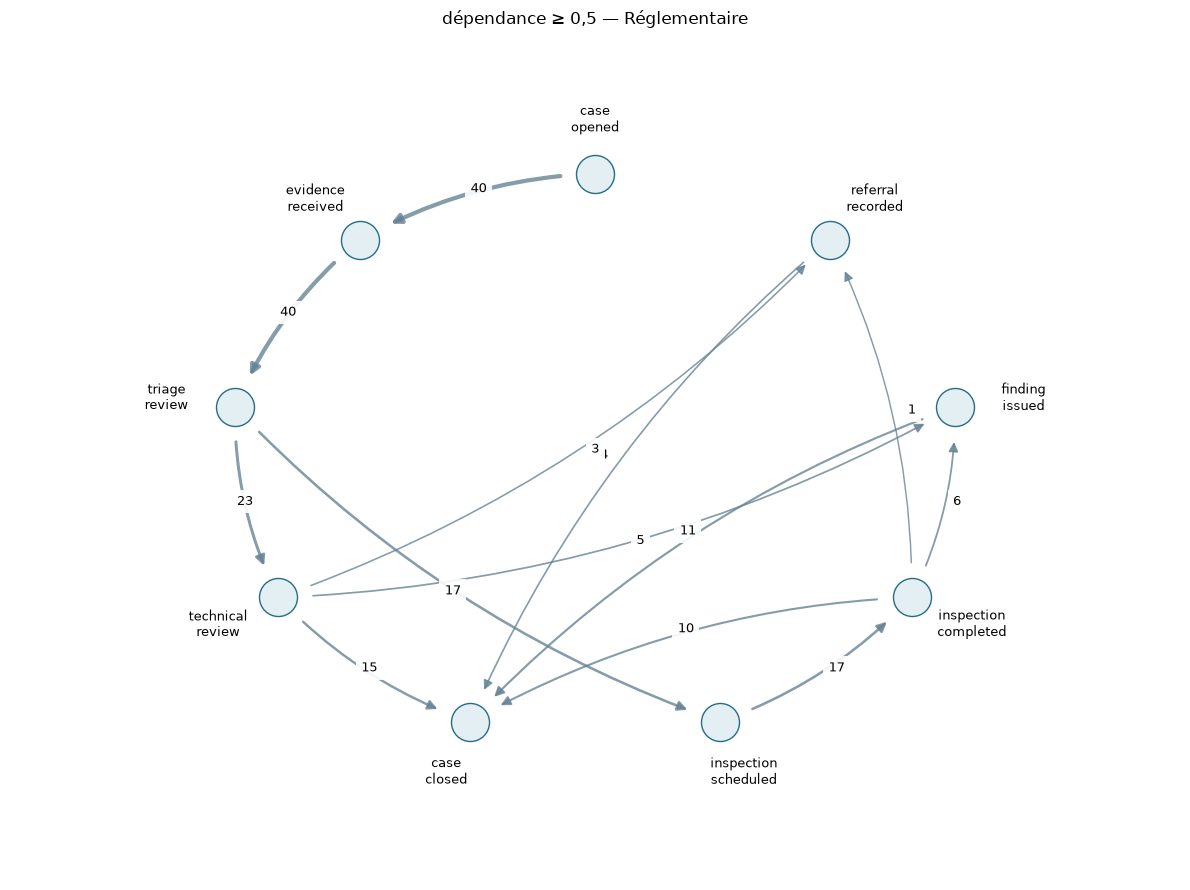

,seuil,aretes_retenues,occurrences_conservees,occurrences_totales
0,0.5,13,192,192
1,0.8,11,188,192
2,0.9,8,173,192


,depart,arrivee,poids,nb_dossiers,delai_median,delai_max,poids_inverse,dependance,support_dossiers,frequence_conditionnelle
6,request_submitted,technical_review,60,60,4.000000,6.000000,0,0.983607,1.000000,0.952381
1,access_started,access_completed,54,54,0.750000,0.750000,0,0.981818,0.900000,1.000000
0,access_completed,closure_recorded,54,54,1.916667,2.333333,0,0.981818,0.900000,1.000000
4,authorization_granted,access_started,54,54,4.333333,10.375000,0,0.981818,0.900000,1.000000
11,technical_review,wildlife_review,46,46,3.000000,5.000000,0,0.978723,0.766667,0.766667
13,wildlife_review,authorization_granted,28,28,3.000000,10.000000,0,0.965517,0.466667,0.608696
10,technical_review,authorization_granted,12,12,6.000000,6.000000,0,0.923077,0.200000,0.200000
14,wildlife_review,security_review,12,12,4.000000,4.000000,0,0.923077,0.200000,0.260870
8,security_review,authorization_granted,11,11,6.000000,6.000000,0,0.916667,0.183333,0.916667
2,authorization_denied,closure_recorded,6,6,2.000000,2.000000,0,0.857143,0.100000,0.666667


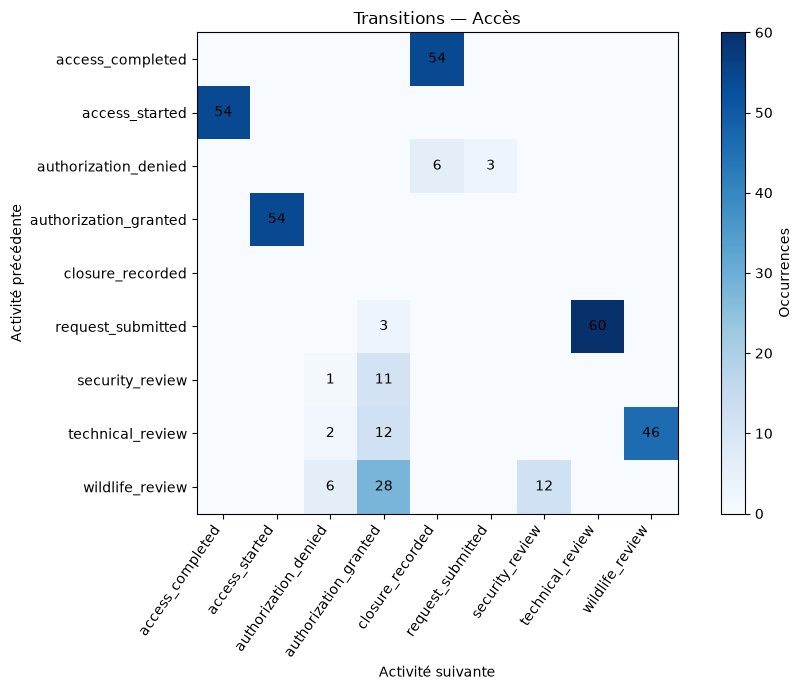

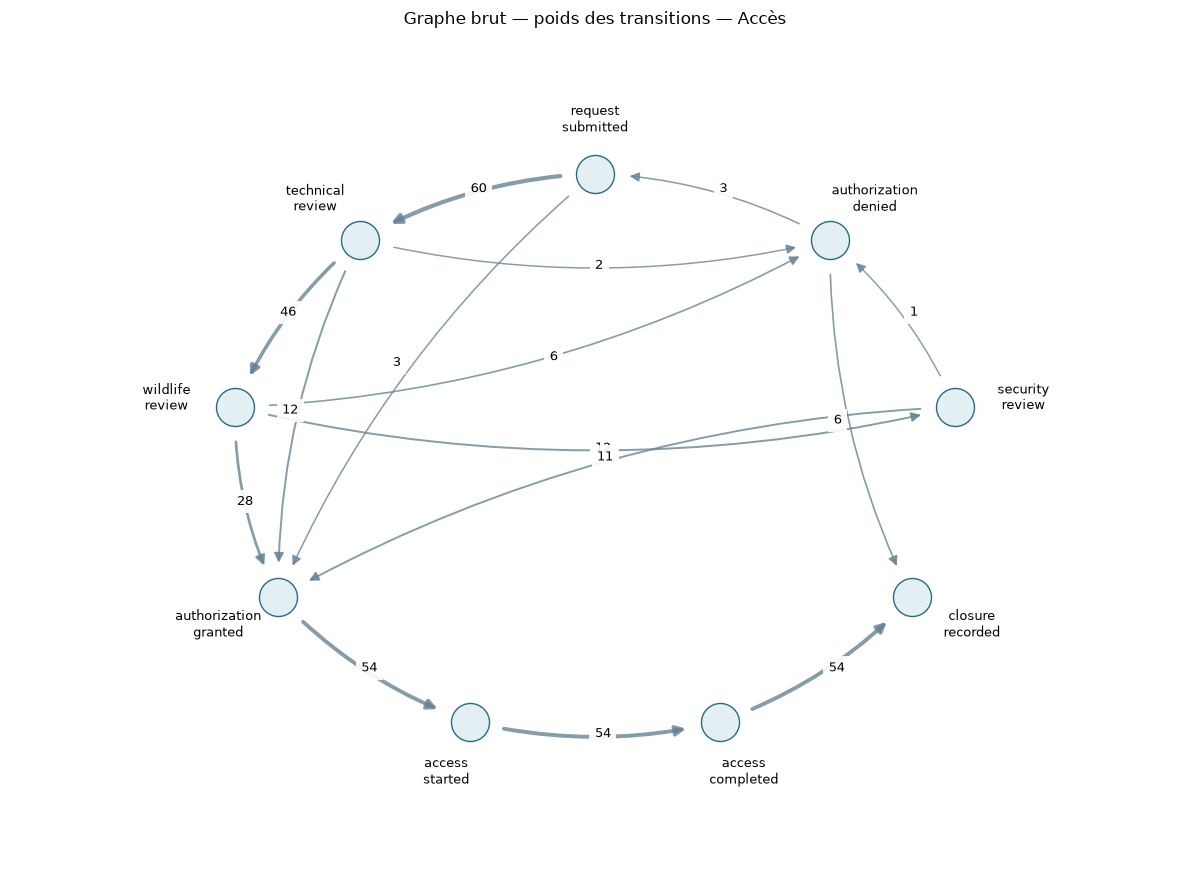

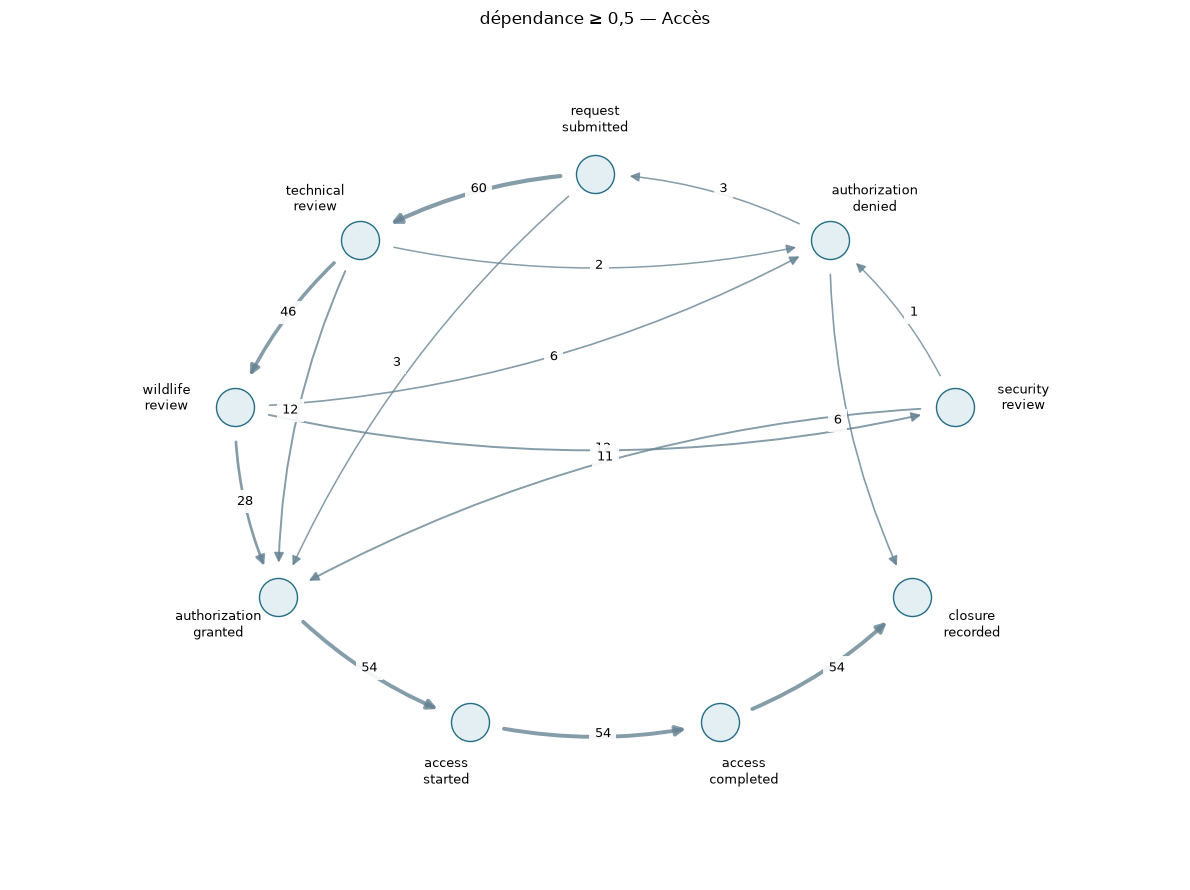

,seuil,aretes_retenues,occurrences_conservees,occurrences_totales
0,0.5,15,352,352
1,0.8,11,343,352
2,0.9,9,331,352


In [18]:
for d, t, suffix in [(reg, trans_reg, 'reg'), (acc, trans_acc, 'acces')]:
    display(t)
    matrice(t, 'Transitions — ' + d.domaine.iloc[0], '02_matrice_'+suffix)
    ordre = list(d.activity_norm.drop_duplicates())
    graphe(t, ordre, 'Graphe brut — poids des transitions — '+d.domaine.iloc[0], '03_graphe_'+suffix)
    graphe(t, ordre, 'dépendance ≥ 0,5 — '+d.domaine.iloc[0], '04_heuristique_'+suffix, .5)
    display(pd.DataFrame([{'seuil': s, 'aretes_retenues': int(t.dependance.ge(s).sum()),
        'occurrences_conservees': int(t.loc[t.dependance.ge(s), 'poids'].sum()),
        'occurrences_totales': int(t.poids.sum())} for s in [.5, .8, .9]]))

Les tableaux donnent le nombre de passages entre deux activités. Les graphes reprennent ces liens avec leur poids. Les versions filtrées permettent de voir les passages les plus marqués.

En observant les graphes, j’ai remarqué que tous les dossiers ne suivaient pas le même parcours. Certains passent par une revue technique, tandis que d’autres comportent une inspection. Dans les demandes d’accès, on retrouve aussi des refus qui sont suivis d’une nouvelle demande. J’ai conservé ces retours, car ils font partie de l’histoire du dossier.

## 5. Recherche des dossiers à examiner

Après avoir identifié les parcours les plus fréquents, je me suis intéressé aux dossiers qui semblaient différents des autres. J’ai regardé les durées plus longues ou plus courtes, les parcours qui n’apparaissaient qu’une seule fois et les étapes qui semblaient manquer. Pour comparer les durées, j’ai utilisé une méthode abordée en cours en tenant compte de la catégorie de chaque dossier.

J’ai également vérifié l’ordre de certaines étapes, notamment pour les autorisations d’accès et les clôtures. Ces vérifications m’ont permis de relever des situations à examiner plus précisément. Toutefois, un dossier signalé n’est pas forcément incorrect : une revue technique réalisée auparavant peut encore être valable après une nouvelle demande.

**Durées atypiques**

In [19]:
bornes = resumes.groupby(['domaine', 'categorie']).duree_jours.agg(
    n='size', q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75)).reset_index()
bornes['iqr'] = bornes.q3-bornes.q1
bornes['borne_basse'] = bornes.q1-1.5*bornes.iqr
bornes['borne_haute'] = bornes.q3+1.5*bornes.iqr
scores = resumes.merge(bornes, on=['domaine', 'categorie'], validate='many_to_one')
scores['duree_atypique'] = scores.n.ge(5) & (scores.duree_jours.lt(scores.borne_basse) | scores.duree_jours.gt(scores.borne_haute))
scores['variante_unique'] = scores.effectif_variante.eq(1)
display(bornes)

,domaine,categorie,n,q1,q3,iqr,borne_basse,borne_haute
0,Accès,demande_acces,60,17.0,34.083333,17.083333,-8.625,59.708333
1,Réglementaire,corporate_transparency,5,18.0,18.000000,0.000000,18.000,18.000000
2,Réglementaire,environmental_complaint,13,18.0,19.000000,1.000000,16.500,20.500000
3,Réglementaire,medical_audit,5,18.0,18.000000,0.000000,18.000,18.000000
4,Réglementaire,procurement_review,5,18.0,18.000000,0.000000,18.000,18.000000
5,Réglementaire,shipment_inspection,7,18.0,18.000000,0.000000,18.000,18.000000
6,Réglementaire,wildlife_inspection,5,35.0,35.000000,0.000000,35.000,35.000000


**Signalements**

In [20]:
alertes = []
def alerter(domaine, dossier, regle, references, detail):
    alertes.append(dict(domaine=domaine, dossier=dossier, regle=regle,
                        references=references, detail=detail))

for r in scores.itertuples():
    if r.variante_unique:
        alerter(r.domaine, r.dossier, 'variante_unique', r.references,
                f'1 dossier parmi {r.effectif_categorie} de la catégorie {r.categorie}')
    if r.duree_atypique:
        alerter(r.domaine, r.dossier, 'duree_IQR', r.references,
                f'{r.duree_jours:g} jours ; bornes [{r.borne_basse:g}, {r.borne_haute:g}] ; n={r.n}')

**Ordre des étapes**

In [21]:
for d in [reg, acc]:
    for dossier, g in d.groupby('dossier'):
        vus, cycle, ids = [], [], []
        for r in g.itertuples():
            a = r.activity_norm
            refs = ' | '.join(ids + [r.event_id])
            if r.rupture_statut:
                alerter(r.domaine, dossier, 'rupture_statut', refs,
                        f'{r.statut_attendu} → previous_status={r.previous_status_norm}')
            if a == 'request_submitted': cycle = []
            if a == 'access_started' and 'authorization_granted' not in cycle:
                alerter(r.domaine, dossier, 'acces_sans_autorisation', refs, 'Aucune autorisation dans le cycle courant')
            if a == 'authorization_granted' and 'technical_review' not in cycle:
                alerter(r.domaine, dossier, 'autorisation_sans_nouvelle_revue', refs,
                        'Pas de revue technique depuis la dernière demande ; vérifier la validité de la revue antérieure')
            if a == 'case_closed' and not {'technical_review', 'inspection_completed'}.intersection(vus):
                alerter(r.domaine, dossier, 'cloture_sans_examen', refs, 'Aucun examen technique ni inspection achevée antérieure')
            if a == 'closure_recorded' and not {'access_completed', 'authorization_denied'}.intersection(cycle):
                alerter(r.domaine, dossier, 'cloture_acces_sans_issue', refs, 'Ni fin d’accès ni refus dans le cycle courant')
            vus.append(a); cycle.append(a); ids.append(r.event_id)
        if g.egalite_horodatage.any():
            alerter(g.domaine.iloc[0], dossier, 'ordre_ambigu', ' | '.join(g.event_id), 'Horodatages égaux : départage technique à valider')

**Dossiers à examiner**

In [22]:
signalements = pd.DataFrame(alertes, columns=['domaine', 'dossier', 'regle', 'references', 'detail'])
display(signalements)
display(signalements.groupby(['domaine', 'regle']).dossier.nunique().rename('dossiers_signales').to_frame())
print('Absence d’alerte ≠ preuve de conformité. Une alerte ≠ preuve d’irrégularité.')

,domaine,dossier,regle,references,detail
0,Réglementaire,REG-2022-0006,variante_unique,RGE-000031 | RGE-000032 | RGE-000033 | RGE-000034 | RGE-000035 | RGE-000036 | RGE-000037,1 dossier parmi 7 de la catégorie shipment_inspection
1,Réglementaire,REG-2022-0007,duree_IQR,RGE-000038 | RGE-000039 | RGE-000040 | RGE-000041 | RGE-000042 | RGE-000043,"22 jours ; bornes [16.5, 20.5] ; n=13"
2,Réglementaire,REG-2024-0009,variante_unique,RGE-000050 | RGE-000051 | RGE-000052 | RGE-000053 | RGE-000054 | RGE-000055 | RGE-000056,1 dossier parmi 7 de la catégorie shipment_inspection
3,Réglementaire,REG-2024-0009,duree_IQR,RGE-000050 | RGE-000051 | RGE-000052 | RGE-000053 | RGE-000054 | RGE-000055 | RGE-000056,"19 jours ; bornes [18, 18] ; n=7"
4,Réglementaire,REG-2025-0010,duree_IQR,RGE-000057 | RGE-000058 | RGE-000059 | RGE-000060 | RGE-000061 | RGE-000062,"22 jours ; bornes [16.5, 20.5] ; n=13"
5,Accès,ACC-2023-0013,variante_unique,ACE-000095 | ACE-000096 | ACE-000097 | ACE-000098 | ACE-000099 | ACE-000100 | ACE-000101 | ACE-0...,1 dossier parmi 60 de la catégorie demande_acces
6,Accès,ACC-2021-0010,autorisation_sans_nouvelle_revue,ACE-000071 | ACE-000072 | ACE-000073 | ACE-000074 | ACE-000075 | ACE-000076,Pas de revue technique depuis la dernière demande ; vérifier la validité de la revue antérieure
7,Accès,ACC-2023-0013,autorisation_sans_nouvelle_revue,ACE-000095 | ACE-000096 | ACE-000097 | ACE-000098 | ACE-000099 | ACE-000100 | ACE-000101,Pas de revue technique depuis la dernière demande ; vérifier la validité de la revue antérieure
8,Accès,ACC-2024-0015,autorisation_sans_nouvelle_revue,ACE-000112 | ACE-000113 | ACE-000114 | ACE-000115 | ACE-000116 | ACE-000117,Pas de revue technique depuis la dernière demande ; vérifier la validité de la revue antérieure


dossiers_signales
domaine       regle                                              
Accès         autorisation_sans_nouvelle_revue                  3
              variante_unique                                   1
Réglementaire duree_IQR                                         3
              variante_unique                                   2

Absence d’alerte ≠ preuve de conformité. Une alerte ≠ preuve d’irrégularité.


Sept dossiers distincts sont signalés par les règles utilisées. Trois demandes d’accès ont été autorisées sans nouvelle revue technique enregistrée après la dernière demande. Ce point demande une vérification du contexte de chaque dossier.

**Demandes réexaminées**

In [23]:
ids_revision = signalements.loc[signalements.regle.eq('autorisation_sans_nouvelle_revue'), 'dossier'].unique()
display(acc.loc[acc.dossier.isin(ids_revision),
    ['dossier', 'event_id', 'date', 'activity_norm', 'delai_jours', 'previous_status', 'new_status', 'outcome']])

,dossier,event_id,date,activity_norm,delai_jours,previous_status,new_status,outcome
186,ACC-2021-0010,ACE-000071,2021-04-19 09:00:00,request_submitted,NaN,draft,submitted,request logged
187,ACC-2021-0010,ACE-000072,2021-04-25 09:00:00,technical_review,6.000000,submitted,technical_review,technical review completed
188,ACC-2021-0010,ACE-000073,2021-04-30 09:00:00,wildlife_review,5.000000,technical_review,wildlife_review,wildlife conditions recorded
189,ACC-2021-0010,ACE-000074,2021-05-06 09:00:00,authorization_denied,6.000000,wildlife_review,returned,additional conditions required
190,ACC-2021-0010,ACE-000075,2021-05-08 09:00:00,request_submitted,2.000000,returned,resubmitted,conditions updated
191,ACC-2021-0010,ACE-000076,2021-05-10 09:00:00,authorization_granted,2.000000,resubmitted,authorized,authorization issued
192,ACC-2021-0010,ACE-000077,2021-05-20 18:00:00,access_started,10.375000,authorized,active,access commenced
193,ACC-2021-0010,ACE-000078,2021-05-21 03:00:00,access_completed,0.375000,active,completed,field work completed
194,ACC-2021-0010,ACE-000079,2021-05-23 11:00:00,closure_recorded,2.333333,completed,closed,case closed
292,ACC-2023-0013,ACE-000095,2023-10-09 09:00:00,request_submitted,NaN,draft,submitted,request logged


**Dossiers sans alerte**

In [24]:
temoins = scores.loc[~scores.dossier.isin(signalements.dossier)].sort_values('dossier')
display(temoins[['domaine', 'dossier', 'categorie', 'duree_jours', 'parcours']].head(5))
if len(temoins):
    temoin = temoins.iloc[0].dossier
    display(pd.concat([reg, acc]).loc[lambda d: d.dossier.eq(temoin),
        ['dossier', 'event_id', 'date', 'activity_norm', 'delai_jours']])

,domaine,dossier,categorie,duree_jours,parcours
40,Accès,ACC-2015-0029,demande_acces,17.0,request_submitted → technical_review → wildlife_review → authorization_granted → access_started ...
41,Accès,ACC-2015-0034,demande_acces,17.0,request_submitted → technical_review → authorization_granted → access_started → access_completed...
42,Accès,ACC-2016-0046,demande_acces,17.0,request_submitted → technical_review → authorization_granted → access_started → access_completed...
43,Accès,ACC-2017-0025,demande_acces,17.0,request_submitted → technical_review → authorization_granted → access_started → access_completed...
44,Accès,ACC-2017-0039,demande_acces,17.0,request_submitted → technical_review → wildlife_review → authorization_granted → access_started ...


,dossier,event_id,date,activity_norm,delai_jours
0,ACC-2015-0029,ACE-000207,2015-11-01 09:00:00,request_submitted,NaN
1,ACC-2015-0029,ACE-000208,2015-11-05 09:00:00,technical_review,4.000000
2,ACC-2015-0029,ACE-000209,2015-11-08 09:00:00,wildlife_review,3.000000
3,ACC-2015-0029,ACE-000210,2015-11-11 09:00:00,authorization_granted,3.000000
4,ACC-2015-0029,ACE-000211,2015-11-15 17:00:00,access_started,4.333333
5,ACC-2015-0029,ACE-000212,2015-11-16 11:00:00,access_completed,0.750000
6,ACC-2015-0029,ACE-000213,2015-11-18 09:00:00,closure_recorded,1.916667


## 6. Liens avec les autres fichiers

Dans un second temps, j’ai cherché à relier les dossiers aux autres données du projet. Les identifiants présents dans les fichiers m’ont permis de retrouver les sites, les expéditions, les organisations et les mémos qui sont mentionnés dans les événements. Quand une référence ne correspondait à aucune donnée disponible, je l’ai conservée pour pouvoir la signaler.

J’ai aussi dû faire attention aux expéditions qui comportaient plusieurs trajets. Avant de les rapprocher des dossiers, j’ai regroupé ces trajets afin de ne pas compter plusieurs fois le même envoi.

**Sites, organisations et expéditions**

In [25]:
sites = tables['monitoring_sites']
entites = tables['registered_entities']
exp = tables['shipments'].copy()
exp['depart'] = dates(exp.dispatch_time, 'shipments', 'dispatch_time')
exp['arrivee'] = dates(exp.arrival_time, 'shipments', 'arrival_time')
display(exp.loc[exp.arrivee.lt(exp.depart), ['shipment_number', 'shipment_leg', 'dispatch_time', 'arrival_time']])
exp_resume = exp.groupby('shipment_number', as_index=False).agg(
    troncons=('shipment_leg', 'size'), premier_depart=('depart', 'min'), derniere_arrivee=('arrivee', 'max'),
    categories=('item_category', lambda s: ' | '.join(sorted(s.dropna().unique()))),
    autorisations=('authorization_class', lambda s: ' | '.join(sorted(s.dropna().unique()))))

,shipment_number,shipment_leg,dispatch_time,arrival_time


**Contrôle des correspondances**

In [26]:
audit_liens = []
def relier(refs, gauche, cible, droite, nom):
    n_abs = int(refs[gauche].isna().sum())
    refs = refs.dropna(subset=[gauche]).drop_duplicates()
    resultat = refs.merge(cible, left_on=gauche, right_on=droite,
                          how='left', validate='many_to_one', indicator=True)
    assert len(resultat) == len(refs)
    audit_liens.append({'relation': nom, 'lignes_sans_reference': n_abs, 'liens_distincts': len(refs),
        'resolus': int(resultat._merge.eq('both').sum()),
        'non_resolus': int(resultat._merge.eq('left_only').sum())})
    return resultat

**Liens avec les sites**

In [27]:
liens_sites_reg = relier(reg[['dossier', 'related_site_code']].drop_duplicates(),
    'related_site_code', sites, 'site_code', 'Dossiers → sites')
liens_sites_acc = relier(acc[['dossier', 'site_code']].drop_duplicates(),
    'site_code', sites, 'site_code', 'Accès → sites')

**Liens avec les expéditions**

In [28]:
liens_exp = relier(reg[['dossier', 'related_shipment_number']].drop_duplicates(),
    'related_shipment_number', exp_resume, 'shipment_number', 'Dossiers → expéditions')

**Liens avec les organisations**

In [29]:
liens_org_reg = relier(reg[['dossier', 'subject_registration_number', 'subject_name']].drop_duplicates(),
    'subject_registration_number', entites, 'registration_number', 'Dossiers → organisations')
liens_org_acc = relier(acc[['dossier', 'requesting_registration_number', 'requesting_organization_name']].drop_duplicates(),
    'requesting_registration_number', entites, 'registration_number', 'Accès → organisations')

**Liens avec les mémos**

In [30]:
memos = tables['institutional_memos'].copy()
memos['date'] = dates(memos.document_date, 'institutional_memos', 'document_date')
liens_memos = relier(memos[['document_id', 'date', 'subject_line', 'related_case_number', 'related_shipment_number']],
    'related_case_number', resumes[['dossier', 'domaine', 'duree_jours']], 'dossier', 'Mémos → dossiers')

**Bilan des liens**

In [31]:
display(pd.DataFrame(audit_liens))
for nom, t in [('Sites', liens_sites_reg), ('Expéditions', liens_exp), ('Mémos', liens_memos),
               ('Organisations des accès', liens_org_acc)]:
    print(nom)
    display(t.head(12))
    if t._merge.eq('left_only').any():
        print('Références non résolues :')
        display(t.loc[t._merge.eq('left_only')])

,relation,lignes_sans_reference,liens_distincts,resolus,non_resolus
0,Dossiers → sites,20,20,20,0
1,Accès → sites,0,60,60,0
2,Dossiers → expéditions,25,15,15,0
3,Dossiers → organisations,12,28,13,15
4,Accès → organisations,10,50,18,32
5,Mémos → dossiers,20,10,10,0


Sites


,dossier,related_site_code,site_code,site_name,site_category,region,jurisdiction,latitude,...,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status,_merge
0,REG-2016-0033,AVL-GRB,AVL-GRB,Tamarind Ridge Monitoring Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.3725,...,186.4,mixed_agriculture,not applicable,commercial or research orchard,2018-01-01,<NA>,active,both
1,REG-2018-0001,AVL-MAR,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.41,...,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,<NA>,active,both
2,REG-2018-0017,KNT-VLB,KNT-VLB,Vireo Ridge Monitoring Site,habitat monitoring,Kintara Karst Cluster,Kintara Republic,4.4848,...,161.2,mixed_forest,not applicable,none recorded,2016-01-01,<NA>,active,both
3,REG-2018-0029,KNT-XAC,KNT-XAC,Heron Meadow Monitoring Site,habitat monitoring,Kintara Karst Cluster,Kintara Republic,5.0398,...,271.9,protected_forest,not applicable,none recorded,2017-01-01,<NA>,active,both
4,REG-2019-0002,KNT-KES,KNT-KES,Kestrel Cavern Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.68,...,248.0,karst_habitat,managed,none recorded,2016-01-01,<NA>,active,both
5,REG-2020-0003,TMB-PEL,TMB-PEL,Pelagos Grove Monitoring Site,habitat monitoring,Tembara Coastal Cluster,Tembara Commonwealth,2.27,...,261.0,coastal_habitat,not applicable,none recorded,2016-01-01,<NA>,active,both
6,REG-2021-0004,AVL-MAR,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.41,...,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,<NA>,active,both
7,REG-2021-0005,AVL-MAR,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.41,...,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,<NA>,active,both
8,REG-2021-0027,KNT-TEX,KNT-TEX,Banyan Reach Monitoring Site,habitat monitoring,Kintara Karst Cluster,Kintara Republic,4.6917,...,82.6,mixed_forest,not applicable,none recorded,2016-01-01,<NA>,active,both
9,REG-2022-0006,TMB-NAC,TMB-NAC,Nacre Coast Cave Site,cave monitoring,Tembara Coastal Cluster,Tembara Commonwealth,2.11,...,299.0,coastal_habitat,managed,none recorded,2016-01-01,<NA>,active,both


Expéditions


,dossier,related_shipment_number,shipment_number,troncons,premier_depart,derniere_arrivee,categories,autorisations,_merge
0,REG-2018-0001,SHP-2018-00032,SHP-2018-00032,1,2018-05-25 09:00:00,2018-05-29 01:00:00,biological_sample,restricted,both
1,REG-2019-0002,SHP-2018-00007,SHP-2018-00007,1,2018-03-23 09:00:00,2018-03-25 08:00:00,biological_sample,expedited,both
2,REG-2020-0003,SHP-2019-00009,SHP-2019-00009,1,2019-08-09 09:00:00,2019-08-11 18:00:00,biological_sample,expedited,both
3,REG-2020-0028,SHP-2019-00009,SHP-2019-00009,1,2019-08-09 09:00:00,2019-08-11 18:00:00,biological_sample,expedited,both
4,REG-2021-0004,SHP-2021-00028,SHP-2021-00028,1,2021-05-21 09:00:00,2021-05-23 20:00:00,biological_sample,ordinary,both
5,REG-2021-0005,SHP-2021-00028,SHP-2021-00028,1,2021-05-21 09:00:00,2021-05-23 20:00:00,biological_sample,ordinary,both
6,REG-2022-0006,SHP-2022-00018,SHP-2022-00018,1,2022-02-18 09:00:00,2022-02-19 22:00:00,biological_sample,expedited,both
7,REG-2022-0007,SHP-2023-00071,SHP-2023-00071,1,2023-11-10 09:00:00,2023-11-12 05:00:00,biological_sample,restricted,both
8,REG-2022-0016,SHP-2021-00019,SHP-2021-00019,1,2021-05-12 13:00:00,2021-05-13 02:00:00,refrigeration_service,ordinary,both
9,REG-2022-0022,SHP-2016-00012,SHP-2016-00012,1,2016-10-18 12:00:00,2016-10-19 02:00:00,agricultural_equipment,ordinary,both


Mémos


,document_id,date,subject_line,related_case_number,related_shipment_number,dossier,domaine,duree_jours,_merge
0,MEM-510030,2024-03-02,Internal Operations Memorandum 58,ACC-2019-0005,<NA>,ACC-2019-0005,Accès,34.083333,both
1,MEM-510080,2019-08-09,Internal Operations Memorandum 59,REG-2024-0036,<NA>,REG-2024-0036,Réglementaire,18.000000,both
2,MEM-510021,2023-04-10,Procurement Justification 63,ACC-2018-0024,<NA>,ACC-2018-0024,Accès,17.000000,both
3,MEM-510061,2018-09-17,Procurement Justification 64,REG-2022-0022,<NA>,REG-2022-0022,Réglementaire,18.000000,both
4,MEM-510022,2022-05-18,Shipment Exception Report 68,ACC-2023-0047,<NA>,ACC-2023-0047,Accès,12.000000,both
5,MEM-510047,2025-10-25,Shipment Exception Report 69,REG-2024-0009,<NA>,REG-2024-0009,Réglementaire,19.000000,both
6,MEM-510067,2021-06-26,Inventory Reconciliation Explanation 73,ACC-2020-0008,<NA>,ACC-2020-0008,Accès,34.083333,both
7,MEM-510090,2024-11-06,Inventory Reconciliation Explanation 74,REG-2024-0036,<NA>,REG-2024-0036,Réglementaire,18.000000,both
8,MEM-510013,2020-07-07,Records Security Instruction 78,ACC-2023-0028,<NA>,ACC-2023-0028,Accès,17.000000,both
9,MEM-510065,2023-12-14,Operations Meeting Record 79,REG-2022-0022,<NA>,REG-2022-0022,Réglementaire,18.000000,both


Organisations des accès


,dossier,requesting_registration_number,requesting_organization_name,registration_number,legal_name,registered_entity_type,registration_date,current_status,registered_address,jurisdiction,declared_activity,parent_registration_number,last_filing_date,_merge
0,ACC-2015-0034,REG-VLN-20015,Orison Facility Management,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
1,ACC-2017-0025,REG-VLN-20009,Valenne Laboratory Materials,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
2,ACC-2017-0039,REG-KNT-20025,Juniper Community Health Foundation,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
3,ACC-2017-0042,REG-TMB-20031,Garnet Scientific Instruments,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
4,ACC-2017-0044,REG-KNT-20037,Blue Heron Monitoring Cooperative,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
5,ACC-2018-0001,REG-AVL-01013,Horizon Field Research Cooperative,REG-AVL-01013,Horizon Field Research Cooperative,research_institute,2002-01-15,active,Eastern Avelora Agricultural Cluster,Avelora Federation,Environmental contractor,<NA>,2025-03-31,both
6,ACC-2018-0002,REG-AVL-01013,Horizon Field Research Cooperative,REG-AVL-01013,Horizon Field Research Cooperative,research_institute,2002-01-15,active,Eastern Avelora Agricultural Cluster,Avelora Federation,Environmental contractor,<NA>,2025-03-31,both
7,ACC-2018-0003,REG-AVL-01013,Horizon Field Research Cooperative,REG-AVL-01013,Horizon Field Research Cooperative,research_institute,2002-01-15,active,Eastern Avelora Agricultural Cluster,Avelora Federation,Environmental contractor,<NA>,2025-03-31,both
8,ACC-2018-0019,REG-VLN-20001,Interregional Procurement Cooperative,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
9,ACC-2018-0024,REG-NDH-20008,Nordhaven Refrigeration Works,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only


Références non résolues :


,dossier,requesting_registration_number,requesting_organization_name,registration_number,legal_name,registered_entity_type,registration_date,current_status,registered_address,jurisdiction,declared_activity,parent_registration_number,last_filing_date,_merge
0,ACC-2015-0034,REG-VLN-20015,Orison Facility Management,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
1,ACC-2017-0025,REG-VLN-20009,Valenne Laboratory Materials,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
2,ACC-2017-0039,REG-KNT-20025,Juniper Community Health Foundation,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
3,ACC-2017-0042,REG-TMB-20031,Garnet Scientific Instruments,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
4,ACC-2017-0044,REG-KNT-20037,Blue Heron Monitoring Cooperative,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
8,ACC-2018-0019,REG-VLN-20001,Interregional Procurement Cooperative,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
9,ACC-2018-0024,REG-NDH-20008,Nordhaven Refrigeration Works,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
10,ACC-2018-0040,REG-TMB-20027,Dune Agricultural Machinery,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
14,ACC-2019-0035,REG-VLN-20016,Lumen Protective Equipment,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only
15,ACC-2019-0036,REG-KNT-20020,Senna Agricultural Research Centre,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,left_only


Les références de sites et d’expéditions présentes dans les dossiers trouvent une correspondance. En revanche, 15 références d’organisations des dossiers réglementaires et 32 références des demandes d’accès ne se retrouvent pas dans le registre fourni.

Ces rapprochements m’ont permis de replacer certains dossiers dans un contexte plus large. Ils restent cependant à interpréter avec prudence. Par exemple, le fait qu’une expédition soit mentionnée dans un dossier ne permet pas, à lui seul, de connaître son rôle. De la même façon, deux organisations qui portent des noms proches ne sont pas nécessairement la même.

## 7. Chronologie des événements

Pour avoir une meilleur vue du projet, j’ai ensuite rassemblé les dates des dossiers, des accès, des commandes, des expéditions, des rencontres et des mémos sur une même frise. Cette chronologie m’a permis de voir quand les événements avaient eu lieu les uns par rapport aux autres. J’ai gardé pour chacun la source et l’identifiant d’origine, afin de pouvoir retrouver les informations dans les fichiers si un événement demandait une vérification.

**Chronologie commune**

In [32]:
parts = []
def chrono(d, temps, source, reference, activite, dossier=None, site=None, envoi=None):
    def col(c):
        return d[c].astype('string') if c is not None else pd.Series(pd.NA, index=d.index, dtype='string')
    parts.append(pd.DataFrame({'date': d[temps], 'source': source, 'reference': col(reference),
        'activite': d[activite].astype('string') if activite in d else activite,
        'dossier': col(dossier), 'site': col(site), 'expedition': col(envoi)}))

**Dossiers, accès et expéditions**

In [33]:
chrono(reg, 'date', 'regulatory_case_events', 'event_id', 'activity_norm', 'dossier', 'related_site_code', 'related_shipment_number')
chrono(acc, 'date', 'site_access_case_events', 'event_id', 'activity_norm', 'dossier', 'site_code')
exp['reference_troncon'] = exp.shipment_number + '/leg=' + exp.shipment_leg
chrono(exp, 'depart', 'shipments', 'reference_troncon', 'départ', envoi='shipment_number')
chrono(exp, 'arrivee', 'shipments', 'reference_troncon', 'arrivée', envoi='shipment_number')

**Dates des commandes**

In [34]:
commandes = tables['purchase_order_lines'].copy()
commandes['date'] = dates(commandes.order_date, 'purchase_order_lines', 'order_date')
assert commandes.groupby('purchase_order_number').date.nunique(dropna=False).le(1).all()
commandes_uniques = commandes.drop_duplicates('purchase_order_number')
chrono(commandes_uniques, 'date', 'purchase_order_lines', 'purchase_order_number', 'commande créée')

**Rencontres et mémos**

In [35]:
rencontres = tables['clinical_encounters'].copy()
rencontres['debut'] = dates(rencontres.encounter_start, 'clinical_encounters', 'encounter_start')
rencontres['fin'] = dates(rencontres.encounter_end, 'clinical_encounters', 'encounter_end')
chrono(rencontres, 'debut', 'clinical_encounters', 'encounter_number', 'début rencontre')
chrono(rencontres, 'fin', 'clinical_encounters', 'encounter_number', 'fin rencontre')
chrono(memos, 'date', 'institutional_memos', 'document_id', 'document_type', 'related_case_number', envoi='related_shipment_number')

**Contrôle des dates**

In [36]:
chronologie_complete = pd.concat(parts, ignore_index=True)
non_dates = chronologie_complete.loc[chronologie_complete.date.isna()]
chronologie = chronologie_complete.dropna(subset=['date']).sort_values(['date', 'source', 'reference']).reset_index(drop=True)
display(pd.DataFrame(audit_dates))
print('Événements non datés exclus de la frise, conservés dans un export :', len(non_dates))
display(chronologie.groupby('source').agg(evenements=('reference', 'size'), debut=('date', 'min'), fin=('date', 'max')))

,source,variable,lignes,absentes,invalides,valeurs_invalides
0,regulatory_case_events,event_time,232,0,0,
1,site_access_case_events,event_time,412,0,0,
2,shipments,dispatch_time,450,0,0,
3,shipments,arrival_time,450,17,0,
4,institutional_memos,document_date,30,0,0,
5,purchase_order_lines,order_date,650,0,0,
6,clinical_encounters,encounter_start,1067,0,0,
7,clinical_encounters,encounter_end,1067,0,0,


Événements non datés exclus de la frise, conservés dans un export : 17


,evenements,debut,fin
source,,,
clinical_encounters,2134,2014-02-18 09:15:00,2026-01-11 15:47:00
institutional_memos,30,2018-01-19 00:00:00,2025-10-25 00:00:00
purchase_order_lines,650,2014-06-24 00:00:00,2025-06-23 00:00:00
regulatory_case_events,232,2016-04-10 10:00:00,2025-05-30 10:00:00
shipments,883,2014-07-10 09:00:00,2025-06-16 03:00:00
site_access_case_events,412,2015-02-15 09:00:00,2025-06-15 11:00:00


Les dates renseignées ont été converties. Il manque toutefois 17 dates d’arrivée dans les expéditions. Ces événements restent dans le tableau des dates manquantes et ne figurent pas sur la frise.

**Frise chronologique globale**

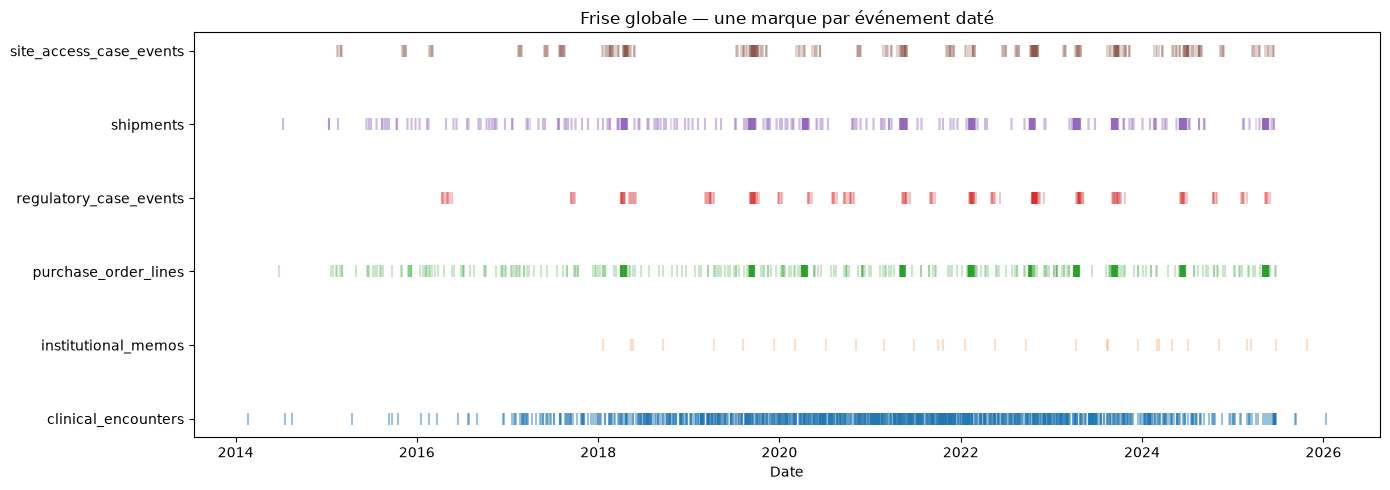

In [37]:
fig, ax = plt.subplots(figsize=(14, 5))
for y, (source, g) in enumerate(chronologie.groupby('source', sort=True)):
    ax.scatter(g.date, np.full(len(g), y), marker='|', s=65, alpha=.25, label=source)
labels = sorted(chronologie.source.unique())
ax.set_yticks(range(len(labels)), labels)
ax.set(title='Frise globale — une marque par événement daté', xlabel='Date')
figure('05_chronologie_globale')

**Choix d’un dossier**

In [38]:
candidats = sorted(set(signalements.dossier) & set(liens_memos.loc[liens_memos._merge.eq('both'), 'dossier']))
cas_etude = candidats[0] if candidats else resume_reg.iloc[0].dossier
envois_cas = reg.loc[reg.dossier.eq(cas_etude), 'related_shipment_number'].dropna().unique()
frise = chronologie.loc[chronologie.dossier.eq(cas_etude).fillna(False)
    | (chronologie.source.eq('shipments') & chronologie.expedition.isin(envois_cas))].copy()
frise['nature_lien'] = np.where(frise.dossier.eq(cas_etude).fillna(False), 'référence dossier', 'expédition citée')
display(Markdown(f'### Étude détaillée : `{cas_etude}`'))
display(frise)
display(signalements.loc[signalements.dossier.eq(cas_etude)])

### Étude détaillée : `REG-2024-0009`

,date,source,reference,activite,dossier,site,expedition,nature_lien
3845,2024-05-31 09:00:00,regulatory_case_events,RGE-000050,case_opened,REG-2024-0009,AVL-MAR,SHP-2024-00011,référence dossier
3846,2024-05-31 09:00:00,shipments,SHP-2024-00011/leg=1,départ,<NA>,<NA>,SHP-2024-00011,expédition citée
3859,2024-06-03 03:00:00,shipments,SHP-2024-00011/leg=1,arrivée,<NA>,<NA>,SHP-2024-00011,expédition citée
3866,2024-06-04 09:00:00,regulatory_case_events,RGE-000051,evidence_received,REG-2024-0009,AVL-MAR,SHP-2024-00011,référence dossier
3877,2024-06-06 09:00:00,regulatory_case_events,RGE-000052,triage_review,REG-2024-0009,AVL-MAR,SHP-2024-00011,référence dossier
3886,2024-06-08 09:00:00,regulatory_case_events,RGE-000053,inspection_scheduled,REG-2024-0009,AVL-MAR,SHP-2024-00011,référence dossier
3898,2024-06-11 09:00:00,regulatory_case_events,RGE-000054,inspection_completed,REG-2024-0009,AVL-MAR,SHP-2024-00011,référence dossier
3904,2024-06-12 09:00:00,regulatory_case_events,RGE-000055,referral_recorded,REG-2024-0009,AVL-MAR,SHP-2024-00011,référence dossier
3940,2024-06-19 09:00:00,regulatory_case_events,RGE-000056,case_closed,REG-2024-0009,AVL-MAR,SHP-2024-00011,référence dossier
4338,2025-10-25 00:00:00,institutional_memos,MEM-510047,shipment_report,REG-2024-0009,<NA>,<NA>,référence dossier


,domaine,dossier,regle,references,detail
2,Réglementaire,REG-2024-0009,variante_unique,RGE-000050 | RGE-000051 | RGE-000052 | RGE-000053 | RGE-000054 | RGE-000055 | RGE-000056,1 dossier parmi 7 de la catégorie shipment_inspection
3,Réglementaire,REG-2024-0009,duree_IQR,RGE-000050 | RGE-000051 | RGE-000052 | RGE-000053 | RGE-000054 | RGE-000055 | RGE-000056,"19 jours ; bornes [18, 18] ; n=7"


**Frise d’un dossier**

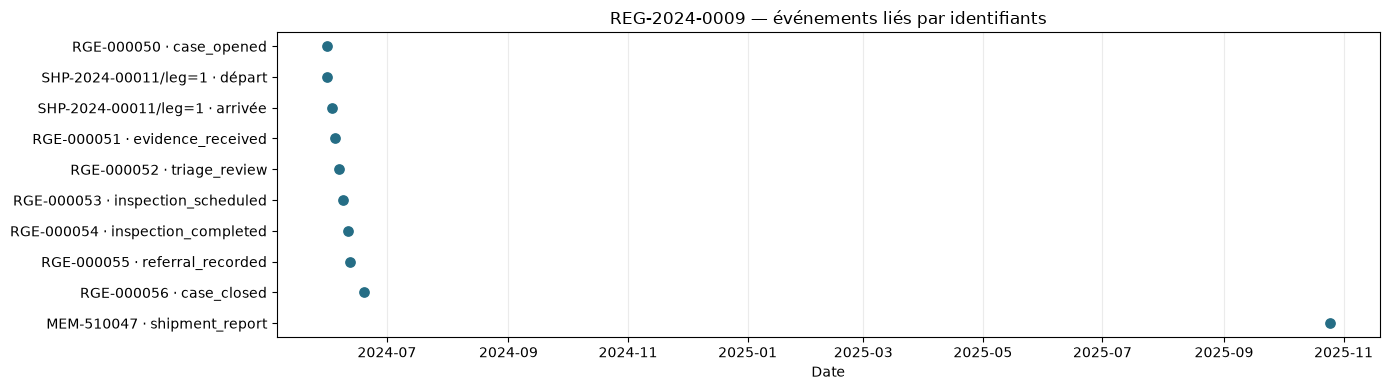

In [39]:
fig, ax = plt.subplots(figsize=(14, max(4, len(frise)*.34)))
ax.scatter(frise.date, np.arange(len(frise)), color='#256d85', s=45)
ax.set_yticks(range(len(frise)), frise.reference + ' · ' + frise.activite)
ax.invert_yaxis()
ax.set(title=f'{cas_etude} — événements liés par identifiants', xlabel='Date')
ax.grid(axis='x', alpha=.25)
figure('06_frise_dossier')

## 8. Résultats et limites

À la fin de cette analyse, j’ai rassemblé les principaux résultats et les dossiers qui méritaient d’être revus. Certains dossiers apparaissaient plusieurs fois parce qu’ils étaient signalés pour différentes raisons. Pour présenter un total plus juste, je ne les ai comptés qu’une seule fois, tout en conservant le détail des signalements et les références des événements.

**Bilan de mon analyse**

Après avoir retiré les lignes identiques, j’ai pu retrouver 40 dossiers réglementaires et 60 demandes d’accès. Les premiers contiennent 232 événements et les seconds 412 événements. J’ai ensuite calculé leur durée : la médiane est de 18 jours pour les dossiers réglementaires et de 17 jours pour les demandes d’accès.

En suivant les étapes de chaque dossier, j’en ai repéré 7 qui méritent d’être regardés de plus près. Parmi les demandes d’accès, 3 ont été autorisées sans nouvelle revue technique enregistrée après la dernière demande : ACC-2021-0010, ACC-2023-0013, ACC-2024-0015. Cela ne veut pas forcément dire qu’une étape a été oubliée, car une revue précédente peut encore être valable.

J’ai également comparé les 13 plaintes environnementales entre elles. 2 ont une durée inhabituelle : REG-2022-0007, REG-2025-0010. Les références des événements se trouvent dans les tableaux précédents, ce qui permet de vérifier ces exemples.

Enfin, les liens avec les sites, les expéditions et les mémos m’ont aidé à replacer certains dossiers dans l’ensemble du projet. Ils donnent des pistes pour continuer le travail avec le groupe, même si les données ne suffisent pas à expliquer à elles seules les différences observées.

Au total, les 40 dossiers réglementaires ont une durée médiane de 18 jours et les 60 demandes d’accès une durée médiane de 17 jours. Les exemples signalés restent des dossiers à examiner, pas des conclusions sur leur traitement.

**Limites de l’analyse**

Même si ce travail m’a permis de repérer des parcours inhabituels, je ne peux pas conclure qu’un dossier présente une irrégularité sur cette seule base. Certaines catégories contiennent peu de dossiers, ce qui rend les comparaisons moins solides. Il est également possible que des étapes n’aient pas été enregistrées dans les fichiers.

Enfin, lorsque plusieurs événements portent la même date, leur ordre exact peut être difficile à retrouver. Les liens que j’ai établis dépendent aussi des identifiants disponibles. J’ai donc tenu compte de ces limites au moment de présenter les résultats.

## 9. Résultats à partager avec le groupe

Pour terminer, j’ai enregistré les tableaux et les graphiques obtenus pendant mon analyse. Le groupe pourra les utiliser lors de la rédaction du rapport commun, et les identifiants conservés permettront de vérifier les exemples présentés. La suite du travail consistera à rassembler les différentes parties du projet, à relire les résultats ensemble puis à exécuter de nouveau le notebook final avant le rendu.

**Export des tableaux**

In [41]:
exports = {
    'audit_fichiers': audit_fichiers, 'audit_valeurs_manquantes': audit_manquants,
    'audit_cles': audit_cles, 'audit_dates': pd.DataFrame(audit_dates),
    'audit_jointures': pd.DataFrame(audit_liens),
    'evenements_reglementaires_nettoyes': reg, 'evenements_acces_nettoyes': acc,
    'dossiers_reglementaires': resume_reg, 'dossiers_acces': resume_acc,
    'variantes': variantes, 'transitions_reglementaires': trans_reg, 'transitions_acces': trans_acc,
    'bornes_IQR': bornes, 'scores_tous_dossiers': scores, 'dossiers_atypiques': signalements,
    'liens_dossiers_sites': liens_sites_reg, 'liens_acces_sites': liens_sites_acc,
    'liens_dossiers_expeditions': liens_exp, 'liens_dossiers_memos': liens_memos,
    'liens_dossiers_organisations': liens_org_reg, 'liens_acces_organisations': liens_org_acc,
    'chronologie_globale': chronologie, 'evenements_non_dates': non_dates, 'frise_dossier': frise}
for nom, table in exports.items():
    table.to_csv(OUT / (nom+'.csv'), index=False, encoding='utf-8-sig')

**Contrôle final**

In [42]:
assert all(hashlib.sha256((ROOT / r.fichier).read_bytes()).hexdigest() == r.sha256
           for r in audit_fichiers.itertuples())
assert len(chronologie) + len(non_dates) == len(chronologie_complete)
assert not pd.DataFrame(audit_dates).invalides.any(), 'Consulter audit_dates avant interprétation.'
print(f'{len(exports)} tableaux exportés ; sources inchangées ; contrôles terminés.')
print('Figures :', len(list(OUT.glob('*.png'))))

24 tableaux exportés ; sources inchangées ; contrôles terminés.
Figures : 9
